In [15]:
from dotenv import load_dotenv
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from groq import Groq

load_dotenv("../.env")
groq_client = Groq()


In [16]:
class LLMState(TypedDict):
    query: str
    response: str

graph = StateGraph(LLMState)

In [ ]:
def ask_groq(query: str) -> str:
    """Handles the raw API communication with Groq."""
    try:
        completion = groq_client.chat.completions.create(
            model="qwen/qwen3.8-27b",
            messages=[
                {"role": "user", "content": query}
            ],
            temperature=0.7
        )
        return completion.choices[0].message.content
    except Exception as e:
        # Handle API errors gracefully
        return f"Error communicating with Groq: {str(e)}"


def generate_response(state: LLMState) -> dict:
    """LangGraph node that manages state updates."""
    query = state["query"]
    response = ask_groq(query)

    # Return only the modified fields. LangGraph merges this automatically.
    return {"response": response}


In [18]:
graph.add_node("generate_response", generate_response)

In [19]:
graph.add_edge(START, "generate_response")
graph.add_edge("generate_response", END)

In [20]:
workflow = graph.compile()

In [21]:
initial_state = {"query": "how does neutrinos change there type?"}
final_state = workflow.invoke(initial_state)
print(final_state)

{'query': 'how does neutrinos change there type?', 'response': 'The phenomenon you are referring to is called **neutrino oscillation**. It is one of the most fascinating discoveries in modern physics, proving that neutrinos have mass (which was not part of the original Standard Model of particle physics).\n\nHere is a step-by-step explanation of how neutrinos "change" their type (flavor):\n\n### 1. The Three Flavors\nNeutrinos come in three "flavors" that correspond to their associated charged leptons:\n- **Electron neutrino** ($\\nu_e$)\n- **Muon neutrino** ($\\nu_\\mu$)\n- **Tau neutrino** ($\\nu_\\tau$)\n\nA neutrino is produced in a specific flavor depending on the nuclear reaction that created it. For example:\n- In the Sun: Electron neutrinos ($\\nu_e$) are produced by nuclear fusion.\n- In the Earth\'s atmosphere: Muon neutrinos ($\\nu_\\mu$) are produced by cosmic ray collisions.\n\n### 2. The Key Concept: Flavor States vs. Mass States\nThe reason neutrinos can change type lies

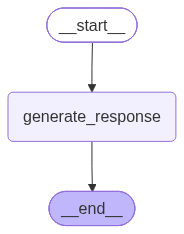

In [22]:
from IPython.display import Image

Image(workflow.get_graph().draw_mermaid_png())

# only works in jupyter nb